<a href="https://colab.research.google.com/github/AsimaZaheer/BCI-Research/blob/main/EEG_Cross_Dataset_BCI_IV2a_PhysioNet_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install packages (Google Colab)

In [1]:
!pip -q install --upgrade mne scikit-learn scipy pandas matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


## 2. Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
print("Google Drive mounted:", Path("/content/drive/MyDrive").exists())


Mounted at /content/drive
Google Drive mounted: True


## 3. Imports and reproducibility

In [3]:
import os, re, glob, zipfile, random, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import mne, torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.linalg import fractional_matrix_power
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("ERROR")
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| MNE:", mne.__version__, "| PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab choose Runtime > Change runtime type > T4 GPU.")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda | MNE: 1.13.2 | PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 4. Configuration — set your Google Drive dataset folder

In [4]:
# Change this to the folder in your Google Drive that contains the EEG files.
# Example: /content/drive/MyDrive/EEG_Datasets
DATA_ROOT = Path("/content/drive/MyDrive/BCI Datasets/")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Results will be saved back to Google Drive.
OUT = Path("/content/drive/MyDrive/EEG_Cross_Dataset_Outputs")
OUT.mkdir(parents=True, exist_ok=True)

TARGET_SFREQ=128
LOW_CUT, HIGH_CUT = 8.0, 30.0
EPOCH_TMIN, EPOCH_TMAX = -0.5, 3.5
BATCH_SIZE=64
EPOCHS=40
LEARNING_RATE=1e-3
WEIGHT_DECAY=1e-4
DROPOUT=0.5
NUM_WORKERS=2
CLASS_NAMES=["left_hand","right_hand","feet"]
CLASS_TO_ID={name:i for i,name in enumerate(CLASS_NAMES)}

print("Dataset folder:", DATA_ROOT)
print("Output folder:", OUT)
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Please create or correct DATA_ROOT: {DATA_ROOT}")


Dataset folder: /content/drive/MyDrive/BCI Datasets
Output folder: /content/drive/MyDrive/EEG_Cross_Dataset_Outputs


## 5. Find and extract the datasets from Google Drive

In [5]:
# Colab has mounted Google Drive above; no gdown download is needed.
# Extract ZIP archives found in the selected Drive folder.
for zp in DATA_ROOT.rglob("*.zip"):
    dest=zp.with_suffix("")
    if not dest.exists():
        print("Extracting:", zp)
        with zipfile.ZipFile(zp) as zf:
            zf.extractall(dest)

SEARCH_ROOTS=[DATA_ROOT]

def locate(ext):
    return sorted({p.resolve() for root in SEARCH_ROOTS
                   for p in root.rglob("*"+ext) if p.is_file()})

gdf_files=locate(".gdf")
edf_files=locate(".edf")
print("Found GDF recordings:",len(gdf_files))
print("Found EDF recordings:",len(edf_files))
print("GDF examples:",[p.name for p in gdf_files[:5]])
print("EDF examples:",[p.name for p in edf_files[:5]])
if not gdf_files or not edf_files:
    raise RuntimeError(
        "Both .gdf and .edf files are required. Check DATA_ROOT. "
        "If the folder is shared with you, add a shortcut to it in My Drive."
    )


Extracting: /content/drive/MyDrive/BCI Datasets/BCICIV_2a_gdf.zip
Extracting: /content/drive/MyDrive/BCI Datasets/eegmmidb-1.0.0.zip
Found GDF recordings: 18
Found EDF recordings: 1526
GDF examples: ['A01E.gdf', 'A01T.gdf', 'A02E.gdf', 'A02T.gdf', 'A03E.gdf']
EDF examples: ['S001R01.edf', 'S001R02.edf', 'S001R03.edf', 'S001R04.edf', 'S001R05.edf']


## 6. Channel mapping, filtering and resampling

In [6]:
# BCI IV-2a standard 22-channel sequence; EOG channels are dropped.
BCI_RENAME={
"EEG-FZ":"Fz","EEG-0":"FC3","EEG-1":"FC1","EEG-2":"FCz","EEG-3":"FC2",
"EEG-4":"FC4","EEG-5":"C5","EEG-C3":"C3","EEG-6":"C1","EEG-CZ":"Cz",
"EEG-7":"C2","EEG-C4":"C4","EEG-8":"C6","EEG-9":"CP3","EEG-10":"CP1",
"EEG-11":"CPz","EEG-12":"CP2","EEG-13":"CP4","EEG-14":"P1","EEG-PZ":"Pz",
"EEG-15":"P2","EEG-16":"POz"}
PREFERRED=list(dict.fromkeys(BCI_RENAME.values()))

def prepare_raw(raw):
    raw=raw.copy()
    picks=mne.pick_types(raw.info,eeg=True,eog=False,ecg=False,emg=False,stim=False,misc=False,exclude=[])
    if len(picks)==0: raise ValueError("No EEG channels found.")
    raw.pick(picks)
    rename={}
    for ch in raw.ch_names:
        key=ch.strip().replace(" ","").upper()
        rename[ch]=BCI_RENAME.get(key,ch.strip().replace(" ","").rstrip("."))
    raw.rename_channels(rename)
    # Avoid duplicate channel names.
    unique=[]
    for ch in raw.ch_names:
        if ch not in unique: unique.append(ch)
    raw.pick_channels(unique,ordered=True)
    raw.filter(LOW_CUT,HIGH_CUT,method="iir",verbose=False)
    raw.resample(TARGET_SFREQ,npad="auto",verbose=False)
    return raw

def subject_bci(path):
    m=re.search(r"([A-D]\d{2})",path.name.upper())
    return m.group(1) if m else path.stem

def physio_info(path):
    m=re.search(r"S(\d{3})R(\d{2})",path.name.upper())
    return ("S"+m.group(1),int(m.group(2))) if m else (None,None)

## 7. Select common electrodes and extract BCI IV-2a epochs

In [7]:
# BCI event codes: 769 left hand, 770 right hand, 771 feet, 772 tongue (excluded).
BCI_MAP={"769":"left_hand","770":"right_hand","771":"feet"}
bci_probe=prepare_raw(mne.io.read_raw_gdf(str(gdf_files[0]),preload=True,verbose=False))
physio_probe_path=next((p for p in edf_files if physio_info(p)[1] in [4,6,8,10,12,14]),None)
if physio_probe_path is None: raise RuntimeError("No PhysioNet imagery runs 4,6,8,10,12,14 found.")
physio_probe=prepare_raw(mne.io.read_raw_edf(str(physio_probe_path),preload=True,verbose=False))
COMMON_CHANNELS=[c for c in PREFERRED if c in bci_probe.ch_names and c in physio_probe.ch_names]
if len(COMMON_CHANNELS)<3:
    raise RuntimeError(f"Only {len(COMMON_CHANNELS)} common electrodes: {COMMON_CHANNELS}. Inspect channel labels.")
print("Common electrodes:",COMMON_CHANNELS)

def extract_bci(path):
    raw=prepare_raw(mne.io.read_raw_gdf(str(path),preload=True,verbose=False))
    missing=set(COMMON_CHANNELS)-set(raw.ch_names)
    if missing: raise ValueError(f"{path.name}: missing channels {missing}")
    raw.pick_channels(COMMON_CHANNELS,ordered=True)
    events,event_id=mne.events_from_annotations(raw,verbose=False)
    selected={}
    for desc,code in event_id.items():
        nums=re.findall(r"\d+",str(desc))
        if nums and nums[-1] in BCI_MAP: selected[desc]=code
    if not selected: raise ValueError(f"No 769/770/771 annotations in {path.name}; got {list(event_id)}")
    ep=mne.Epochs(raw,events,event_id=selected,tmin=EPOCH_TMIN,tmax=EPOCH_TMAX,
                  baseline=(EPOCH_TMIN,0),preload=True,reject_by_annotation=True,
                  event_repeated="drop",verbose=False)
    names=[]
    for code in ep.events[:,-1]:
        desc=next(k for k,v in selected.items() if v==code)
        names.append(BCI_MAP[re.findall(r"\d+",str(desc))[-1]])
    return ep.get_data().astype("float32"),np.array([CLASS_TO_ID[n] for n in names]),subject_bci(path)

Common electrodes: ['Fz', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'P1', 'Pz', 'P2']


## 8. Extract PhysioNet EEGMMIDB motor-imagery epochs

In [8]:
# Imagery runs 4/8/12: T1=left fist, T2=right fist.
# Imagery runs 6/10/14: T1=both fists (excluded), T2=both feet (feet class).
PHYSIO_MAP={
4:{"T1":"left_hand","T2":"right_hand"},
8:{"T1":"left_hand","T2":"right_hand"},
12:{"T1":"left_hand","T2":"right_hand"},
6:{"T2":"feet"},10:{"T2":"feet"},14:{"T2":"feet"}}

def extract_physio(path):
    subject,run=physio_info(path)
    if subject is None or run not in PHYSIO_MAP: return None
    raw=prepare_raw(mne.io.read_raw_edf(str(path),preload=True,verbose=False))
    missing=set(COMMON_CHANNELS)-set(raw.ch_names)
    if missing: raise ValueError(f"{path.name}: missing channels {missing}")
    raw.pick_channels(COMMON_CHANNELS,ordered=True)
    events,event_id=mne.events_from_annotations(raw,verbose=False)
    runmap=PHYSIO_MAP[run]
    selected={d:c for d,c in event_id.items() if str(d).strip().upper() in runmap}
    if not selected: raise ValueError(f"No expected T1/T2 annotations in {path.name}: {list(event_id)}")
    ep=mne.Epochs(raw,events,event_id=selected,tmin=EPOCH_TMIN,tmax=EPOCH_TMAX,
                  baseline=(EPOCH_TMIN,0),preload=True,reject_by_annotation=True,
                  event_repeated="drop",verbose=False)
    names=[]
    for code in ep.events[:,-1]:
        desc=next(k for k,v in selected.items() if v==code)
        names.append(runmap[str(desc).strip().upper()])
    return ep.get_data().astype("float32"),np.array([CLASS_TO_ID[n] for n in names]),subject

## 9. Build unified trials and metadata

In [9]:
Xs,ys,subjs,domains,errors=[],[],[],[],[]
for p in gdf_files:
    try:
        xx,yy,ss=extract_bci(p)
        if len(yy):
            Xs.append(xx); ys.append(yy); subjs.extend(["BCI_"+ss]*len(yy)); domains.extend([0]*len(yy))
    except Exception as e: errors.append((p.name,repr(e)))
for p in edf_files:
    try:
        result=extract_physio(p)
        if result is None: continue
        xx,yy,ss=result
        if len(yy):
            Xs.append(xx); ys.append(yy); subjs.extend(["PHYSIO_"+ss]*len(yy)); domains.extend([1]*len(yy))
    except Exception as e: errors.append((p.name,repr(e)))
if not Xs: raise RuntimeError("No epochs extracted. Check event annotations and file naming.")
X=np.concatenate(Xs).astype(np.float32)
y=np.concatenate(ys).astype(np.int64)
subjects=np.asarray(subjs); domains=np.asarray(domains,dtype=np.int64)
metadata=pd.DataFrame({"subject_id":subjects,
 "dataset_id":np.where(domains==0,"BCI_IV_2a","PhysioNet_EEGMMIDB"),
 "session_id":"unknown","label":[CLASS_NAMES[i] for i in y]})
print("X shape [trials,channels,time]:",X.shape)
display(pd.crosstab(metadata.dataset_id,metadata.label))
print("Read errors:",len(errors),"First few:",errors[:5])
assert np.isfinite(X).all()

X shape [trials,channels,time]: (9316, 11, 513)


label,feet,left_hand,right_hand
dataset_id,,,
BCI_IV_2a,648,648,648
PhysioNet_EEGMMIDB,2455,2479,2438


Read errors: 9 First few: [('A01E.gdf', 'ValueError("No 769/770/771 annotations in A01E.gdf; got [\'1023\', \'1072\', \'276\', \'277\', \'32766\', \'768\', \'783\']")'), ('A02E.gdf', 'ValueError("No 769/770/771 annotations in A02E.gdf; got [\'1023\', \'1072\', \'276\', \'277\', \'32766\', \'768\', \'783\']")'), ('A03E.gdf', 'ValueError("No 769/770/771 annotations in A03E.gdf; got [\'1023\', \'1072\', \'276\', \'277\', \'32766\', \'768\', \'783\']")'), ('A04E.gdf', 'ValueError("No 769/770/771 annotations in A04E.gdf; got [\'1023\', \'1072\', \'276\', \'277\', \'32766\', \'768\', \'783\']")'), ('A05E.gdf', 'ValueError("No 769/770/771 annotations in A05E.gdf; got [\'1023\', \'1072\', \'276\', \'277\', \'32766\', \'768\', \'783\']")')]


## 10. Subject-wise train/validation/test split

In [10]:
if len(np.unique(subjects))<3: raise RuntimeError("Need at least 3 subjects for subject-wise split.")
g1=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED)
trainval_idx,test_idx=next(g1.split(X,y,groups=subjects))
g2=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED+1)
tr_rel,val_rel=next(g2.split(X[trainval_idx],y[trainval_idx],groups=subjects[trainval_idx]))
train_idx=trainval_idx[tr_rel]; val_idx=trainval_idx[val_rel]
for name,idx in [("Train",train_idx),("Validation",val_idx),("Test",test_idx)]:
    print(name,"trials",len(idx),"subjects",len(np.unique(subjects[idx])),
          "classes",np.bincount(y[idx],minlength=3),"domains",np.bincount(domains[idx],minlength=2))
assert not (set(subjects[train_idx])&set(subjects[val_idx]))
assert not (set(subjects[train_idx])&set(subjects[test_idx]))
assert not (set(subjects[val_idx])&set(subjects[test_idx]))

Train trials 5528 subjects 75 classes [1859 1822 1847] domains [ 648 4880]
Validation trials 1862 subjects 19 classes [623 619 620] domains [864 998]
Test trials 1926 subjects 24 classes [645 645 636] domains [ 432 1494]


## 11. Euclidean Alignment (unsupervised per subject)

In [11]:
# Note: this uses unlabeled recordings from each subject, including held-out subjects.
# It is transductive unsupervised alignment, not strict inductive zero-calibration.
def euclidean_align(Xin,sids,eps=1e-6):
    out=np.empty_like(Xin,dtype=np.float32); transforms={}
    for sid in np.unique(sids):
        ix=np.where(sids==sid)[0]
        cov=np.mean([(a@a.T)/a.shape[1] for a in Xin[ix]],axis=0)+eps*np.eye(Xin.shape[1])
        W=fractional_matrix_power(cov,-0.5).real.astype(np.float32)
        out[ix]=np.einsum("ij,njt->nit",W,Xin[ix]).astype(np.float32)
        transforms[sid]=W
    return out,transforms
X_aligned,alignment_transforms=euclidean_align(X,subjects)

## 12. Training-only normalization and train-only augmentation

In [12]:
mean=X_aligned[train_idx].mean(axis=(0,2),keepdims=True)
std=X_aligned[train_idx].std(axis=(0,2),keepdims=True)+1e-6
Xn=((X_aligned-mean)/std).astype(np.float32)

class EEGDataset(Dataset):
    def __init__(self,X,y,d,augment=False):
        self.X=torch.tensor(X,dtype=torch.float32)
        self.y=torch.tensor(y,dtype=torch.long)
        self.d=torch.tensor(d,dtype=torch.long)
        self.augment=augment
    def __len__(self): return len(self.y)
    def __getitem__(self,i):
        x=self.X[i].clone()
        if self.augment:
            if torch.rand(())<0.5: x+=0.02*torch.randn_like(x)
            if torch.rand(())<0.5: x=torch.roll(x,int(torch.randint(-12,13,(1,))),dims=-1)
            if torch.rand(())<0.25: x[int(torch.randint(0,x.shape[0],(1,)))]=0
        return x.unsqueeze(0),self.y[i],self.d[i]

train_ds=EEGDataset(Xn[train_idx],y[train_idx],domains[train_idx],True)
val_ds=EEGDataset(Xn[val_idx],y[val_idx],domains[val_idx])
test_ds=EEGDataset(Xn[test_idx],y[test_idx],domains[test_idx])
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)

## 13. EEGNet-style CNN and domain-adversarial head

In [13]:
USE_DOMAIN_ADVERSARY=True
DOMAIN_LOSS_WEIGHT=0.2

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,alpha): ctx.alpha=alpha; return x.view_as(x)
    @staticmethod
    def backward(ctx,g): return -ctx.alpha*g,None

class EEGNetDomain(nn.Module):
    def __init__(self,nch,nclass=3,dropout=0.5):
        super().__init__()
        self.temporal=nn.Sequential(nn.Conv2d(1,16,(1,64),padding=(0,32),bias=False),nn.BatchNorm2d(16))
        self.spatial=nn.Sequential(nn.Conv2d(16,32,(nch,1),groups=16,bias=False),
            nn.BatchNorm2d(32),nn.ELU(),nn.AvgPool2d((1,4)),nn.Dropout(dropout))
        self.separable=nn.Sequential(nn.Conv2d(32,32,(1,16),padding=(0,8),groups=32,bias=False),
            nn.Conv2d(32,64,(1,1),bias=False),nn.BatchNorm2d(64),nn.ELU(),
            nn.AvgPool2d((1,8)),nn.Dropout(dropout))
        self.pool=nn.AdaptiveAvgPool2d((1,1))
        self.class_head=nn.Linear(64,nclass)
        self.domain_head=nn.Sequential(nn.Linear(64,32),nn.ELU(),nn.Dropout(dropout),nn.Linear(32,2))
    def forward(self,x,alpha=1.0):
        z=self.temporal(x); z=self.spatial(z); z=self.separable(z)
        feat=self.pool(z).flatten(1)
        return self.class_head(feat),self.domain_head(GRL.apply(feat,alpha)),feat

model=EEGNetDomain(X.shape[1],len(CLASS_NAMES),DROPOUT).to(DEVICE)
print(model)

EEGNetDomain(
  (temporal): Sequential(
    (0): Conv2d(1, 16, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (spatial): Sequential(
    (0): Conv2d(16, 32, kernel_size=(11, 1), stride=(1, 1), groups=16, bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (4): Dropout(p=0.5, inplace=False)
  )
  (separable): Sequential(
    (0): Conv2d(32, 32, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=32, bias=False)
    (1): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )

## 14. Train model and save best validation checkpoint

In [14]:
weights=compute_class_weight("balanced",classes=np.arange(3),y=y[train_idx])
class_loss=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
domain_loss=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
def epoch_pass(loader,training=False,epoch=0):
    model.train(training); total=0.; yt=[]; yp=[]
    for xb,yb,db in loader:
        xb,yb,db=xb.to(DEVICE),yb.to(DEVICE),db.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        alpha=2/(1+np.exp(-10*epoch/max(1,EPOCHS-1)))-1
        with torch.set_grad_enabled(training):
            logits,dlogits,_=model(xb,alpha)
            loss=class_loss(logits,yb)
            if USE_DOMAIN_ADVERSARY and len(torch.unique(db))>1:
                loss=loss+DOMAIN_LOSS_WEIGHT*domain_loss(dlogits,db)
            if training:
                loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.0); optimizer.step()
        total+=loss.item()*len(yb); yt.extend(yb.cpu().numpy()); yp.extend(logits.argmax(1).detach().cpu().numpy())
    return total/len(yt),accuracy_score(yt,yp),f1_score(yt,yp,average="macro",zero_division=0)

best=float("inf"); history=[]
BEST_PATH=str(OUT / "best_eegnet_cross_dataset.pt")
for ep in range(EPOCHS):
    a=epoch_pass(train_loader,True,ep); b=epoch_pass(val_loader,False,ep)
    history.append([ep+1,*a,*b])
    if b[0]<best:
        best=b[0]; torch.save(model.state_dict(),BEST_PATH)
    print(f"Epoch {ep+1}/{EPOCHS}: train loss/acc/F1={a[0]:.4f}/{a[1]:.3f}/{a[2]:.3f} | val={b[0]:.4f}/{b[1]:.3f}/{b[2]:.3f}")
history_df=pd.DataFrame(history,columns=["epoch","train_loss","train_acc","train_f1","val_loss","val_acc","val_f1"])
model.load_state_dict(torch.load(BEST_PATH,map_location=DEVICE))
display(history_df.tail())

Epoch 1/40: train loss/acc/F1=1.1790/0.341/0.333 | val=1.1036/0.348/0.287
Epoch 2/40: train loss/acc/F1=1.1594/0.345/0.330 | val=1.1016/0.368/0.365
Epoch 3/40: train loss/acc/F1=1.1551/0.360/0.351 | val=1.0981/0.369/0.328
Epoch 4/40: train loss/acc/F1=1.1532/0.373/0.372 | val=1.0960/0.384/0.359
Epoch 5/40: train loss/acc/F1=1.1519/0.385/0.375 | val=1.0948/0.392/0.356
Epoch 6/40: train loss/acc/F1=1.1777/0.390/0.384 | val=1.0875/0.435/0.434
Epoch 7/40: train loss/acc/F1=1.1612/0.389/0.389 | val=1.0850/0.396/0.376
Epoch 8/40: train loss/acc/F1=1.1387/0.394/0.394 | val=1.0777/0.422/0.412
Epoch 9/40: train loss/acc/F1=1.1366/0.410/0.409 | val=1.0777/0.418/0.382
Epoch 10/40: train loss/acc/F1=1.1328/0.415/0.414 | val=1.0734/0.422/0.404
Epoch 11/40: train loss/acc/F1=1.1295/0.423/0.421 | val=1.0754/0.412/0.382
Epoch 12/40: train loss/acc/F1=1.1417/0.413/0.412 | val=1.0786/0.419/0.383
Epoch 13/40: train loss/acc/F1=1.1332/0.418/0.416 | val=1.0743/0.437/0.418
Epoch 14/40: train loss/acc/F1=1.1

,epoch,train_loss,train_acc,train_f1,val_loss,val_acc,val_f1
35,36,1.107423,0.437410,0.436695,1.064153,0.472073,0.448625
36,37,1.118534,0.444826,0.443445,1.064365,0.441461,0.428105
37,38,1.114485,0.432706,0.432601,1.068340,0.446294,0.420108
38,39,1.112336,0.441570,0.439372,1.068018,0.429108,0.397488
39,40,1.120060,0.436686,0.436032,1.066494,0.429646,0.389697


## 15. Training curves and held-out subject evaluation

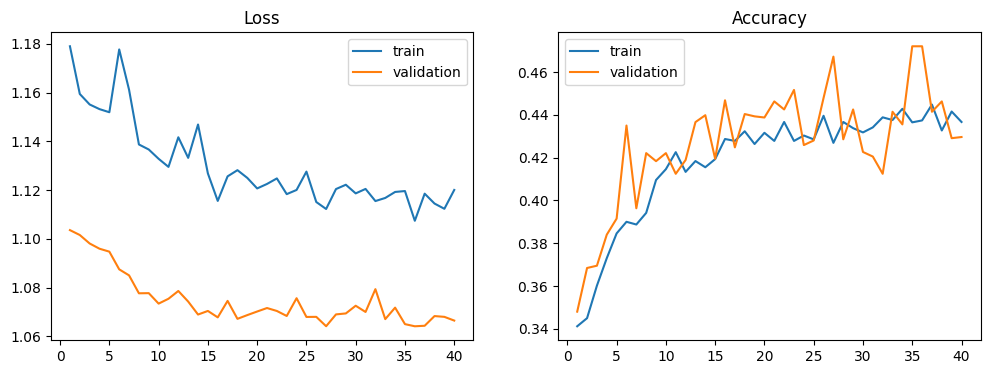

Accuracy 0.43094496365524404 Balanced accuracy 0.4300741065769587 Macro-F1 0.41899942354058956
              precision    recall  f1-score   support

   left_hand       0.40      0.53      0.46       645
  right_hand       0.43      0.51      0.47       645
        feet       0.50      0.24      0.33       636

    accuracy                           0.43      1926
   macro avg       0.44      0.43      0.42      1926
weighted avg       0.44      0.43      0.42      1926



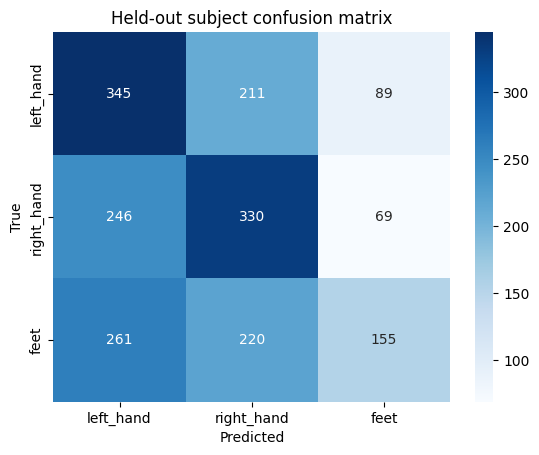

BCI IV-2a n 432 accuracy 0.44212962962962965 macro-F1 0.3905946255002859
PhysioNet n 1494 accuracy 0.42771084337349397 macro-F1 0.42038017957401924


In [15]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(history_df.epoch,history_df.train_loss,label="train")
ax[0].plot(history_df.epoch,history_df.val_loss,label="validation"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history_df.epoch,history_df.train_acc,label="train")
ax[1].plot(history_df.epoch,history_df.val_acc,label="validation"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

def predict(loader):
    yt=[]; yp=[]; dd=[]
    model.eval()
    with torch.no_grad():
        for xb,yb,db in loader:
            logits,_,_=model(xb.to(DEVICE),0.0)
            yt.extend(yb.numpy()); yp.extend(logits.argmax(1).cpu().numpy()); dd.extend(db.numpy())
    return np.array(yt),np.array(yp),np.array(dd)
yt,yp,td=predict(test_loader)
print("Accuracy",accuracy_score(yt,yp),"Balanced accuracy",balanced_accuracy_score(yt,yp),
      "Macro-F1",f1_score(yt,yp,average="macro",zero_division=0))
print(classification_report(yt,yp,labels=[0,1,2],target_names=CLASS_NAMES,zero_division=0))
sns.heatmap(confusion_matrix(yt,yp,labels=[0,1,2]),annot=True,fmt="d",cmap="Blues",
            xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Held-out subject confusion matrix"); plt.show()
for d,name in [(0,"BCI IV-2a"),(1,"PhysioNet")]:
    m=td==d
    if m.any(): print(name,"n",m.sum(),"accuracy",accuracy_score(yt[m],yp[m]),
                       "macro-F1",f1_score(yt[m],yp[m],average="macro",zero_division=0))

## 16. One-way cross-dataset transfer (train BCI → test PhysioNet and reverse)

In [16]:
def transfer(src,dst,epochs=20):
    tr=train_idx[domains[train_idx]==src]; te=test_idx[domains[test_idx]==dst]
    if not len(tr) or not len(te):
        print("Skipped: source train or target test split is empty."); return None
    net=EEGNetDomain(X.shape[1],3,DROPOUT).to(DEVICE)
    opt=torch.optim.Adam(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    loss_fn=nn.CrossEntropyLoss()
    dl=DataLoader(EEGDataset(Xn[tr],y[tr],domains[tr],True),batch_size=BATCH_SIZE,shuffle=True)
    tl=DataLoader(EEGDataset(Xn[te],y[te],domains[te]),batch_size=BATCH_SIZE)
    for _ in range(epochs):
        net.train()
        for xb,yb,_ in dl:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE); opt.zero_grad()
            logits,_,_=net(xb,0.0); loss=loss_fn(logits,yb); loss.backward(); opt.step()
    net.eval(); truth=[]; pred=[]
    with torch.no_grad():
        for xb,yb,_ in tl:
            logits,_,_=net(xb.to(DEVICE),0.0)
            truth.extend(yb.numpy()); pred.extend(logits.argmax(1).cpu().numpy())
    result={"train_domain":src,"test_domain":dst,"n_test":len(truth),
            "accuracy":accuracy_score(truth,pred),
            "macro_f1":f1_score(truth,pred,average="macro",zero_division=0)}
    print(result); return result
transfer_results=[r for r in [transfer(0,1),transfer(1,0)] if r is not None]
display(pd.DataFrame(transfer_results))

{'train_domain': 0, 'test_domain': 1, 'n_test': 1494, 'accuracy': 0.34605087014725566, 'macro_f1': 0.2549850952180333}
{'train_domain': 1, 'test_domain': 0, 'n_test': 432, 'accuracy': 0.4236111111111111, 'macro_f1': 0.32910089009627064}


,train_domain,test_domain,n_test,accuracy,macro_f1
0,0,1,1494,0.346051,0.254985
1,1,0,432,0.423611,0.329101


## 17. Interpretability: input-gradient channel saliency

,channel,saliency
2,C3,0.000054
0,Fz,0.000042
4,Cz,0.000039
7,C6,0.000033
10,P2,0.000033
3,C1,0.000032
6,C4,0.000031
9,Pz,0.000026
5,C2,0.000025
1,C5,0.000022


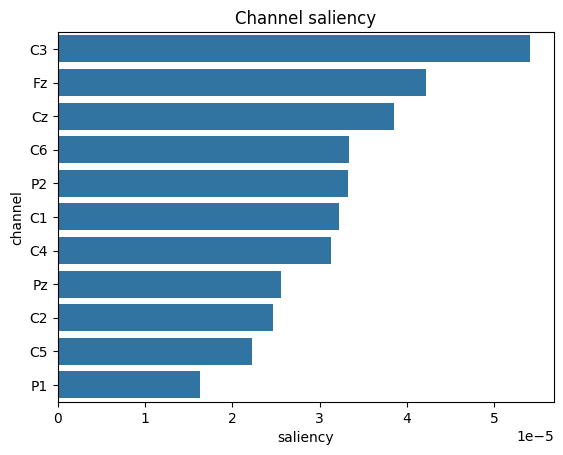

In [17]:
# Gradient saliency proxy (Grad-CAM-style; not canonical Grad-CAM).
model.eval(); sal=np.zeros(X.shape[1],dtype=float); n=0
for xb,yb,db in test_loader:
    xb=xb.to(DEVICE).requires_grad_(True)
    logits,_,_=model(xb,0.0)
    score=logits.gather(1,yb.to(DEVICE).view(-1,1)).sum()
    model.zero_grad(set_to_none=True); score.backward()
    sal+=xb.grad.detach().abs().mean(dim=(0,1,3)).cpu().numpy(); n+=len(yb)
sal/=max(1,n)
saliency_df=pd.DataFrame({"channel":COMMON_CHANNELS,"saliency":sal}).sort_values("saliency",ascending=False)
display(saliency_df)
sns.barplot(data=saliency_df,x="saliency",y="channel"); plt.title("Channel saliency"); plt.show()

## 18. Electrode pruning and robustness

In [18]:
ch_index={c:i for i,c in enumerate(COMMON_CHANNELS)}
least=saliency_df.sort_values("saliency").channel.tolist()
def score_array(arr):
    dl=DataLoader(EEGDataset(arr,y[test_idx],domains[test_idx]),batch_size=BATCH_SIZE)
    truth=[]; pred=[]; model.eval()
    with torch.no_grad():
        for xb,yb,_ in dl:
            logits,_,_=model(xb.to(DEVICE),0.0)
            truth.extend(yb.numpy()); pred.extend(logits.argmax(1).cpu().numpy())
    return accuracy_score(truth,pred),f1_score(truth,pred,average="macro",zero_division=0)
prune=[]
for k in sorted(set([0,max(1,len(least)//4),max(1,len(least)//2)])):
    arr=Xn[test_idx].copy()
    for c in least[:k]: arr[:,ch_index[c],:]=0
    ac,mf=score_array(arr); prune.append({"channels_pruned":k,"accuracy":ac,"macro_f1":mf})
pruning_df=pd.DataFrame(prune); display(pruning_df)

robust=[]
for noise,drop in [(0,0),(.05,0),(.10,0),(.20,0),(0,.10),(0,.25),(0,.50)]:
    arr=Xn[test_idx].copy(); rng=np.random.default_rng(SEED)
    if noise: arr+=rng.normal(0,noise,arr.shape).astype(np.float32)
    if drop:
        ids=rng.choice(arr.shape[1],size=max(1,int(round(arr.shape[1]*drop))),replace=False)
        arr[:,ids,:]=0
    ac,mf=score_array(arr); robust.append({"noise_std":noise,"channel_drop_fraction":drop,"accuracy":ac,"macro_f1":mf})
robustness_df=pd.DataFrame(robust); display(robustness_df)

,channels_pruned,accuracy,macro_f1
0,0,0.430945,0.418999
1,2,0.421599,0.393201
2,5,0.388889,0.363011


,noise_std,channel_drop_fraction,accuracy,macro_f1
0,0.00,0.00,0.430945,0.418999
1,0.05,0.00,0.431983,0.418521
2,0.10,0.00,0.423676,0.408935
3,0.20,0.00,0.420042,0.402514
4,0.00,0.10,0.420561,0.417281
5,0.00,0.25,0.339045,0.188663
6,0.00,0.50,0.334891,0.168151


## 19. Efficiency, save model and export results

In [19]:
n_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
dummy=torch.randn(1,1,X.shape[1],X.shape[2],device=DEVICE)
with torch.no_grad():
    for _ in range(10): model(dummy,0.0)
if DEVICE.type=="cuda": torch.cuda.synchronize()
start=time.perf_counter()
with torch.no_grad():
    for _ in range(100): model(dummy,0.0)
if DEVICE.type=="cuda": torch.cuda.synchronize()
latency_ms=(time.perf_counter()-start)*10
print("Trainable parameters:",n_params,"| mean single-trial inference latency (ms):",round(latency_ms,3))

OUT.mkdir(parents=True, exist_ok=True)
torch.save({"model_state_dict":model.state_dict(),"channels":COMMON_CHANNELS,
            "classes":CLASS_NAMES,"target_sfreq":TARGET_SFREQ,
            "bandpass_hz":[LOW_CUT,HIGH_CUT],"normalization_mean":mean,
            "normalization_std":std},OUT/"eegnet_cross_dataset_final.pt")
metadata.to_csv(OUT/"trial_metadata.csv",index=False)
history_df.to_csv(OUT/"training_history.csv",index=False)
saliency_df.to_csv(OUT/"channel_saliency.csv",index=False)
pruning_df.to_csv(OUT/"channel_pruning.csv",index=False)
robustness_df.to_csv(OUT/"robustness_results.csv",index=False)
pd.DataFrame(transfer_results).to_csv(OUT/"cross_dataset_transfer.csv",index=False)
print("Saved:",[p.name for p in OUT.iterdir()])

Trainable parameters: 6501 | mean single-trial inference latency (ms): 0.694
Saved: ['best_eegnet_cross_dataset.pt', 'eegnet_cross_dataset_final.pt', 'trial_metadata.csv', 'training_history.csv', 'channel_saliency.csv', 'channel_pruning.csv', 'robustness_results.csv', 'cross_dataset_transfer.csv']


## 20. Important research limitations

- The notebook implements a practical baseline for the main pipeline, not every proposed study in the diagram.
- PhysioNet T1/T2 meanings depend on run number. The notebook uses imagery runs only and excludes both-fists trials.
- Rest is excluded from the shared task because BCI IV-2a has no directly equivalent explicit rest trial labels.
- The BCI GDF channel mapping assumes the standard 22-channel BCI IV-2a montage naming/order. Inspect `COMMON_CHANNELS` and raw channel labels if your files are converted or renamed.
- The subject-wise split prevents subject overlap, but the dataset may be small or uneven; check class/domain counts printed in the split cell.
- Euclidean Alignment uses unlabeled recordings from each subject, including held-out subjects, so it is transductive.
- Input-gradient saliency is an approximation, not canonical Grad-CAM.
- This notebook has been checked for Python syntax in its code cells. Actual execution and scientific results depend on your exact dataset files, file naming, annotations, Google Colab Internet access, and available compute.